## ÍNDICE DEL PROYECTO

- [Introducción](#introducción)
1. [Análisis y Exploración del Dataset Agrícola (Guasave, Sinaloa)](#1-análisis-y-exploración-del-dataset-agrícola-guasave-sinaloa)
   * [1.1 Carga de Datos y Limpieza de Estructuras](#11-carga-de-datos-y-limpieza-de-estructuras)
   * [1.2 Verificación de Datos Faltantes e Integridad Numérica](#12-verificación-de-datos-faltantes-e-integridad-numérica)
   * [1.3 Mapeo de Entidades y Cultivos (Maíz, Tomate, Chile)](#13-mapeo-de-entidades-y-cultivos-maíz-tomate-chile)
   * [1.4 Resumen Estadístico de Variables (Humedad, Elevación, Salinidad, Temperatura)](#14-resumen-estadístico-de-variables-humedad-elevación-salinidad-temperatura)
2. [Modelado de Sensores y Función Objetivo](#2-modelado-de-sensores-y-función-objetivo)
   * [2.1 Formulación Matemática del Problema Geoespacial](#21-formulación-matemática-del-problema-geoespacial)
   * [2.2 Definición de la Función Objetivo de Cobertura y Prioridad Hídrica](#22-definición-de-la-función-objetivo-de-cobertura-y-prioridad-hídrica)
   * [2.3 Solución Inicial y Configuración de Línea Base (Baseline)](#23-solución-inicial-y-configuración-de-línea-base-baseline)
3. [Desarrollo e Implementación del Algoritmo PSO](#3-desarrollo-e-implementación-del-algoritmo-pso)
   * [3.1 Justificación Teórica de Enjambre de Partículas (PSO)](#31-justificación-teórica-de-enjambre-de-partículas-pso)
   * [3.2 Inicialización de Partículas (Posiciones y Velocidades Geoespaciales)](#32-inicialización-de-partículas-posiciones-y-velocidades-geoespaciales)
   * [3.3 Estructura del Algoritmo PSO (Criterio de Inercia, Cognitivo y Social)](#33-estructura-del-algoritmo-pso-criterio-de-inercia-cognitivo-y-social)
4. [Ejecución de Simulaciones y Registro de Métricas](#4-ejecución-de-simulaciones-y-registro-de-métricas)
   * [4.1 Configuración de Hiperparámetros (W, C1, C2)](#41-configuración-de-hiperparámetros-w-c1-c2)
   * [4.2 Ejecución de la Simulación y Tracking de Cobertura](#42-ejecución-de-la-simulación-y-tracking-de-cobertura)
   * [4.3 Registro de la Mejor Configuración Geoespacial de Sensores](#43-registro-de-la-mejor-configuración-geoespacial-de-sensores)
5. [Evaluación de Rendimiento y Comparativa](#5-evaluación-de-rendimiento-y-comparativa)
   * [5.1 Análisis de Convergencia Visual (Curva de Optimización)](#51-análisis-de-convergencia-visual-curva-de-optimización)
   * [5.2 Cálculo de Eficiencia y Mejora respecto a la Línea Base](#52-cálculo-de-eficiencia-y-mejora-respecto-a-la-línea-base)
6. [Representación Gráfica de Solución Optimizada](#6-representación-gráfica-de-solución-optimizada)
- [Conclusiones y Análisis de Resultados](#conclusiones-y-análisis-de-resultados)

## INTRODUCCIÓN

La región de Guasave, Sinaloa, es uno de los valles agrícolas más productivos de México, destacando en el cultivo de maíz grano (21.7% de la producción estatal), tomate rojo (9.9%) y chile verde. Sin embargo, las prácticas agrícolas intensivas han acelerado la degradación del suelo, provocando la pérdida de materia orgánica (cayendo del 1.5% a menos del 1% en los últimos 20 años), problemas de salinidad por deficiencias de drenaje y procesos de erosión.

Aunque Guasave se sitúa en una llanura costera con altitudes de 10 a 50 msnm, existen microvariaciones en la elevación que afectan directamente la retención del agua. Además, la variabilidad en la salinidad y la temperatura entre las diferentes parcelas exige que la aplicación del riego no sea uniforme, sino adaptada a las necesidades hídricas de cada tipo de cultivo y calidad de suelo.

Para resolver esto, el objetivo del proyecto es determinar la ubicación óptima de sensores de humedad mediante el algoritmo bioinspirado **Enjambre de Partículas (Particle Swarm Optimization - PSO)**. Utilizando datos geoespaciales reales (WGS 84) de 100 puntos de muestreo en Guasave, el algoritmo buscará las coordenadas exactas de latitud y longitud donde los sensores maximicen la cobertura de monitoreo en las áreas con mayor estrés hídrico y salinidad, optimizando el uso del agua en la región.

## 1. ANÁLISIS Y EXPLORACIÓN DEL DATASET AGRÍCOLA (GUASAVE, SINALOA)

En esta primera sección procesamos y exploramos los datos geoespaciales reales de la región de Guasave, Sinaloa. El dataset consta de 100 puntos de muestreo en el campo agrícola con coordenadas reales WGS 84 (Latitud y Longitud), evaluando variables clave como humedad, elevación, salinidad y temperatura.

### 1.1 Carga de Datos y Limpieza de Estructuras

En este punto cargamos el archivo de Excel `datos_agricolas.xlsx` ubicado en la carpeta `Datasets` utilizando la librería `pandas` para estructurar la información en un `DataFrame`.

In [45]:
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fijar semilla aleatoria para garantizar determinismo
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Cargar el dataset desde la carpeta Datasets
df_agricola = pd.read_excel('./Datasets/datos_agricolas.xlsx')

# Limpiar espacios en blanco al inicio o final de los nombres de columnas
df_agricola.columns = df_agricola.columns.str.strip()

print('Carga de datos exitosa.')
print('Total de registros cargados:', len(df_agricola))

Carga de datos exitosa.
Total de registros cargados: 100


In [37]:
df_agricola.head()

,Humedad (%),Cultivo,Elevación (m),Salinidad (dS/m),Temperatura (°C),Latitud,Longitud
0,35.4,Maíz,32.1,1.18,30.9,25.525269,-108.480884
1,20.0,Maíz,40.8,3.30,27.5,25.600618,-108.519701
2,43.3,Maíz,21.9,1.17,31.8,25.577411,-108.465669
3,36.3,Maíz,41.7,2.93,25.3,25.616337,-108.470516
4,17.3,Chile,31.8,1.91,29.1,25.522286,-108.480179


### 1.2 Verificación de Datos Faltantes e Integridad Numérica

Evaluamos la integridad del conjunto de datos mediante las funciones vectorizadas `isnull()` y `sum()` de `pandas` para comprobar la ausencia de valores nulos en cada una de las variables.

In [47]:
# Conteo de valores nulos por columna y total general con pandas
nulos_por_columna = df_agricola.isnull().sum()
total_nulos = nulos_por_columna.sum()

print('=== REVISIÓN DE DATOS FALTANTES ===')
print(nulos_por_columna)
print('\nTotal de valores nulos en el dataset:', total_nulos)

if total_nulos == 0:
    print('El dataset esta completo.')

=== REVISIÓN DE DATOS FALTANTES ===
Humedad (%)         0
Cultivo             0
Elevación (m)       0
Salinidad (dS/m)    0
Temperatura (°C)    0
Latitud             0
Longitud            0
dtype: int64

Total de valores nulos en el dataset: 0
El dataset esta completo.


### 1.3 Mapeo de Entidades y Cultivos (Maíz, Tomate, Chile)

Analizamos la frecuencia y distribución de las parcelas según el tipo de cultivo en Guasave mediante el método `.value_counts()` de `pandas`.

In [49]:
# Frecuencia absoluta y relativa de cultivos con pandas
conteo_cultivos = df_agricola['Cultivo'].value_counts()

print('=== DISTRIBUCIÓN DE CULTIVOS EN GUASAVE ===')
print(conteo_cultivos)

=== DISTRIBUCIÓN DE CULTIVOS EN GUASAVE ===
Cultivo
Maíz      35
Chile     35
Tomate    30
Name: count, dtype: int64


### 1.4 Resumen Estadístico de Variables y Visualización Geoespacial

En este punto realizamos un análisis rápido de la información del campo agrícola mediante dos pasos:

1. **Tabla Estadística:** Utilizamos la función `.describe()` de `pandas` para obtener de forma automática los valores numéricos más importantes del terreno (Humedad, Elevación, Salinidad y Temperatura). Esto nos permite conocer el promedio de cada variable, sus valores mínimos, máximos y el rango de variación en la región.
2. **Mapa Geoespacial:** Generamos una gráfica de dispersión posicionando cada parcela según sus coordenadas reales de Latitud y Longitud (WGS 84). Cada tipo de cultivo (Maíz, Chile y Tomate) se representa con un color diferente para visualizar claramente cómo están distribuidas las parcelas en el mapa de Guasave.

In [40]:
df_agricola.describe()

,Humedad (%),Elevación (m),Salinidad (dS/m),Temperatura (°C),Latitud,Longitud
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,24.896000,29.555000,2.066600,29.583000,25.571391,-108.477358
std,11.339017,11.796339,1.003739,5.244546,0.028709,0.029249
min,5.100000,10.100000,0.540000,20.000000,25.521859,-108.519701
25%,16.125000,20.550000,1.272500,25.500000,25.544724,-108.502368
50%,25.050000,30.400000,1.840000,29.100000,25.570125,-108.480688
75%,33.200000,39.925000,2.975000,33.975000,25.599454,-108.453048
max,44.900000,49.700000,3.950000,40.000000,25.618887,-108.420215


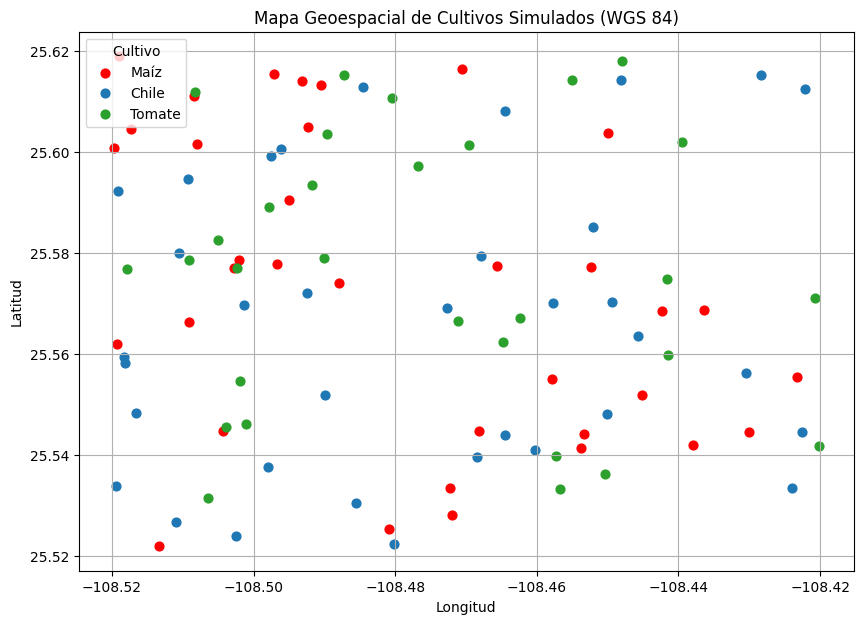

In [51]:
# Gráfica del Mapa Geoespacial Real de Cultivos (WGS 84)
plt.figure(figsize=(10, 7))

colores_cultivos = [('Maíz', 'red'), ('Chile', '#1f77b4'), ('Tomate', '#2ca02c')]

for nombre_cultivo, color_marcador in colores_cultivos:
    filtro_cultivo = df_agricola[df_agricola['Cultivo'] == nombre_cultivo]
    plt.scatter(
        filtro_cultivo['Longitud'], 
        filtro_cultivo['Latitud'], 
        c=color_marcador, 
        label=nombre_cultivo, 
        s=40
    )

plt.title('Mapa Geoespacial de Cultivos Simulados (WGS 84)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend(title='Cultivo')
plt.grid(True)
plt.show()